# Density-Based Spatial Clustering of Applications with Noise (DBSCAN)

## 1) Concept

- Forming clusters along connections among observations in dense regions
- Observation features or distances between observations as inputs, without target labels
- Cluster count determined by connectivity; observations outside all clusters classified as noise

## 2) Terminology

- Epsilon ($\varepsilon$): the maximum distance for two points to be neighbors; written as `eps` in the code and slider
- Epsilon-neighborhood: the set of points within distance epsilon of a reference point, including boundary points and the reference point itself
- `min_samples`: the minimum neighborhood count for a core point, distinct from the total size of a cluster

- Core point: a point with at least `min_samples` observations in its neighborhood
- Border point: a non-core point within the neighborhood of a core point
- Noise point: neither a core point nor a neighbor of any core point

<div style="margin-left:24px;">
<img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-bigdata/main/12-1_Clustering/assets/03_density_neighborhoods.webp" width="512" alt="Core points, border points, and noise defined by neighborhood counts">
</div>

## 3) Methodology

1. Formation of an initial cluster from an unassigned core point's epsilon-neighborhood; registration of newly included points for inspection
2. Selection of an uninspected point; comparison of its full-dataset neighborhood count with `min_samples`
3. For a core point, addition of its neighbors to the cluster and registration of newly included points; for a border point, membership retained without further expansion
4. Repetition of steps 2–3 for remaining uninspected points, excluding duplicate registration of inspected points
5. Completion of the current cluster when no points remain to be inspected
6. Repetition of steps 1–5 from remaining unassigned core points; final assignment of the noise label to points outside all clusters

<div style="margin-left:24px;">
<img src="https://raw.githubusercontent.com/sonamu-jun/introduction-to-bigdata/main/12-1_Clustering/assets/03_cluster_expansion.webp" width="512" alt="DBSCAN cluster expansion through connected core-point neighborhoods">
</div>

- Connected core points can form curved clusters; epsilon limits individual neighborhoods rather than the diameter of the entire cluster
- Increasing epsilon can connect core points and merge clusters; decreasing it can split clusters or increase noise
- Increasing `min_samples` at the same radius makes the core-point condition stricter and can increase border points or noise
- Epsilon and `min_samples` selected instead of a predefined cluster count
- A distance metric also required; Euclidean distance uses straight-line separation, while other metrics can produce different neighborhoods and clusters

## 4) Example Code Execution


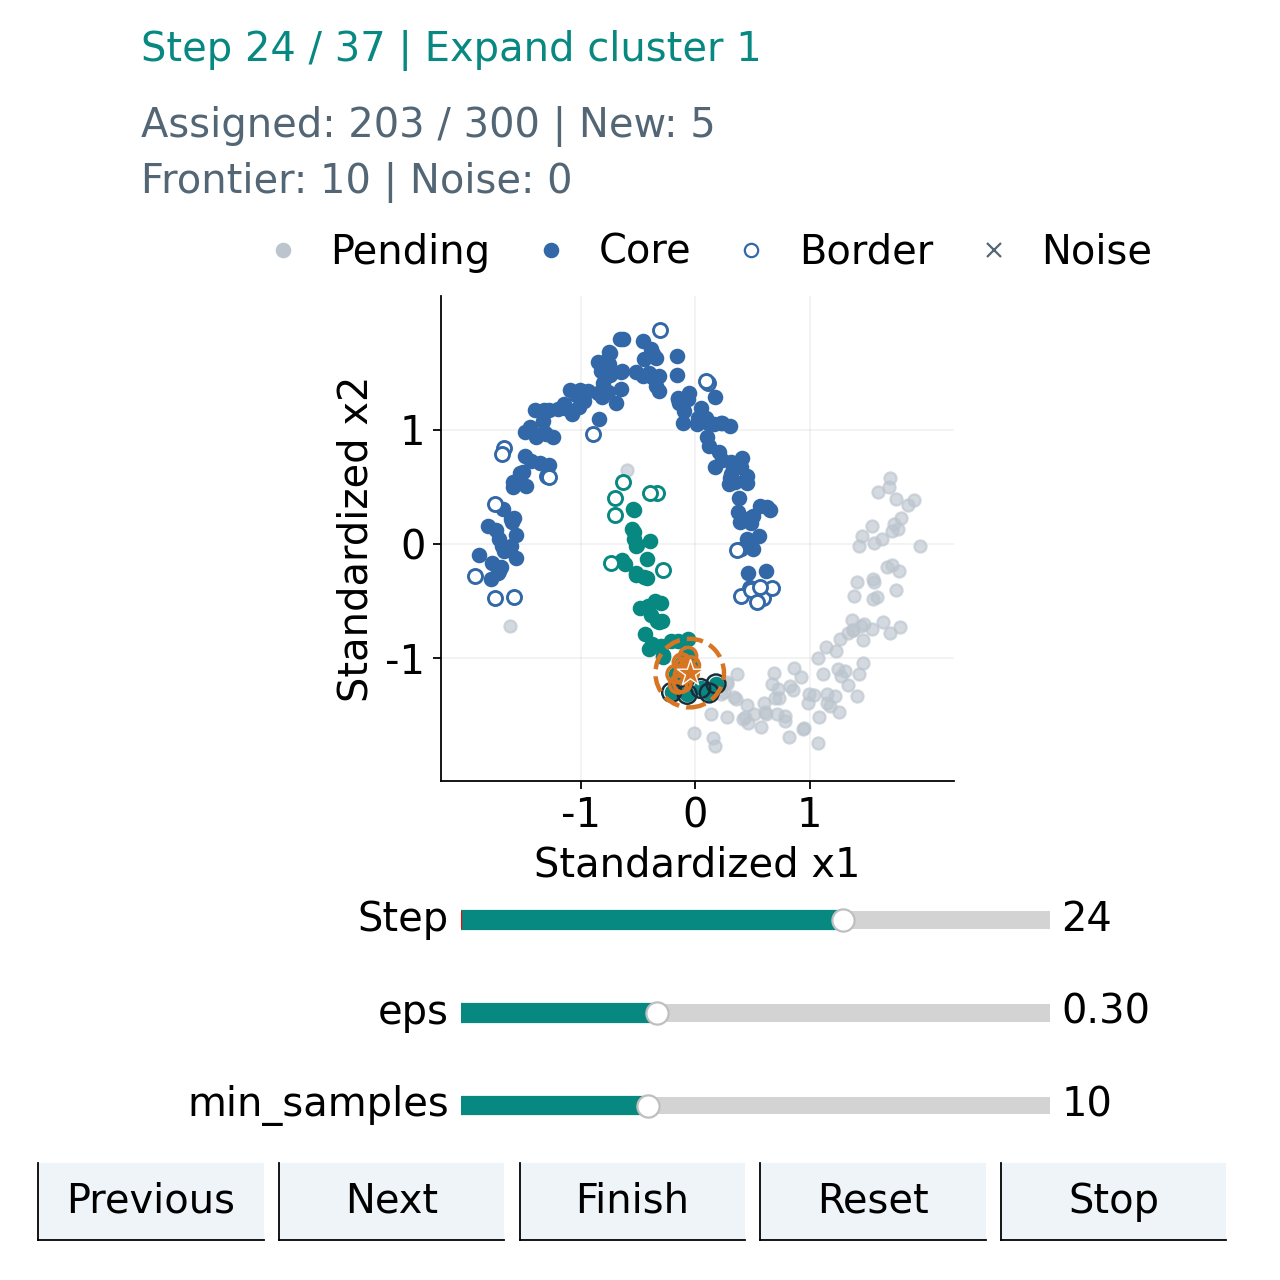

In [1]:
import os
import sys
import io
import numpy as np
import matplotlib

CLUSTERING_STATIC = os.environ.get("CLUSTERING_STATIC") == "1"
CLUSTERING_BROWSER = sys.platform == "emscripten"
if not CLUSTERING_STATIC and not CLUSTERING_BROWSER:
    from IPython import get_ipython
    shell = get_ipython()
    if shell is not None and getattr(shell, "kernel", None) is not None:
        try:
            shell.run_line_magic("matplotlib", "widget")
        except (ImportError, RuntimeError):
            shell.run_line_magic("matplotlib", "inline")

import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from IPython.display import Image, display

plt.rcParams.update({
    "font.size": 18, "axes.labelsize": 18,
    "xtick.labelsize": 18, "ytick.labelsize": 18, "legend.fontsize": 18,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .16, "lines.linewidth": 2.5,
    "axes.unicode_minus": False, "figure.facecolor": "white",
})
BLUE, TEAL, ORANGE, PURPLE = "#3268a8", "#078880", "#d87522", "#8251ac"


for _previous_view in globals().get("_clustering_views", {}).values():
    _previous_view.close()
_clustering_views = {}


class ClusteringExplorer:

    def __init__(self, name, render, sliders, actions=()):
        self.render = render
        self.slider_specs = sliders
        self.controls, self.buttons, self.state = {}, {}, {}
        self.stopped = False
        self.defaults = {key: initial for key, label, low, high, initial, step, fmt in sliders}
        with plt.ioff():
            height = min(8.0, 6.8 + .58 * len(sliders))
            self.figure = plt.figure(figsize=(8, height), dpi=64)
        self.status = self.figure.text(.11, 1 - .38 / height, "", fontsize=18, color=TEAL)
        self.detail = self.figure.text(.11, 1 - .66 / height, "", va="top", fontsize=18, color="#536675", linespacing=1.5)
        bottom = (1.38 + .58 * len(sliders)) / height
        top = 1 - 1.85 / height
        self.plot_bottom = bottom
        self.ax = self.figure.add_axes([.14, bottom, .81, top - bottom])
        for i, (key, label, low, high, initial, step, fmt) in enumerate(sliders):
            y = (.98 + .58 * (len(sliders) - i - 1)) / height
            slider = Slider(self.figure.add_axes([.36, y, .46, .22 / height]),
                            label, low, high, valinit=initial, valstep=step,
                            valfmt=fmt, color=TEAL)
            slider.label.set_fontsize(18)
            slider.valtext.set_fontsize(18)
            slider.on_changed(self.update)
            self.controls[key] = slider
        commands = list(actions) + [("Reset", lambda view: view.reset()),
                                    ("Stop", lambda view: view.stop())]
        self.commands = commands
        width = min(.25, .94 / len(commands) - .012)
        for i, (label, callback) in enumerate(commands):
            button = Button(self.figure.add_axes([.03 + i * (width + .012), .25 / height, width, .48 / height]),
                            label,
                            color="#eef4f7", hovercolor="#d7e9e6")
            button.label.set_fontsize(18)
            button.on_clicked(lambda event, cb=callback: cb(self) if not self.stopped else None)
            self.buttons[label] = button
        self.connections = [self.figure.canvas.mpl_connect("close_event", lambda event: self.stop())]
        _clustering_views[name] = self
        self.update()

    def update(self, _=None):
        if self.stopped:
            return
        self.ax.clear()
        self.state = self.render(self, **{key: slider.val for key, slider in self.controls.items()})
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def set_values(self, **values):
        if self.stopped:
            return
        for key, value in values.items():
            slider = self.controls[key]
            events, drawing = slider.eventson, slider.drawon
            slider.eventson = slider.drawon = False
            slider.set_val(value)
            slider.eventson, slider.drawon = events, drawing
        self.update()

    def reset(self):
        self.set_values(**self.defaults)

    def refresh_local(self):
        if not hasattr(self, "local_image"):
            return
        from matplotlib.transforms import Bbox
        width, height = self.figure.get_size_inches()
        self.figure.canvas.draw()
        bounds = self.ax.get_tightbbox(self.figure.canvas.get_renderer())
        lower = max(0, bounds.y0 / self.figure.dpi - .04)
        buffer = io.BytesIO()
        self.figure.savefig(buffer, format="png", dpi=64, facecolor="white",
                            bbox_inches=Bbox.from_extents(0, lower, width, height))
        self.local_image.value = buffer.getvalue()
        self.syncing_local = True
        for key, control in self.local_controls.items():
            source = self.controls[key]
            if control.value > source.valmax:
                control.value = source.valmax
            control.max = source.valmax
            control.value = source.val
        self.syncing_local = False

    def start_local(self):
        from ipywidgets import Image as WidgetImage, FloatSlider, IntSlider
        from ipywidgets import Button as WidgetButton, HBox, VBox, Layout
        self.syncing_local = False
        self.local_image = WidgetImage(format="png", layout=Layout(
            width="100%", max_width="512px", height="auto"))
        self.local_controls, self.local_buttons = {}, {}
        for key, label, low, high, initial, step, fmt in self.slider_specs:
            slider_type = IntSlider if fmt == "%0.0f" and step == 1 else FloatSlider
            control = slider_type(value=self.controls[key].val, min=low, max=self.controls[key].valmax, step=step,
                                  description=label, readout_format=fmt.replace("%0", ""),
                                  continuous_update=True,
                                  style={"description_width": "130px"},
                                  layout=Layout(width="100%", max_width="512px"))
            def changed(change, key=key):
                if not self.syncing_local and not self.stopped:
                    self.controls[key].set_val(change["new"])
            control.observe(changed, names="value")
            self.local_controls[key] = control
        for label, callback in self.commands:
            button = WidgetButton(description=label, layout=Layout(
                flex="1 1 0", min_width="120px", height="34px", margin="2px"))
            button.on_click(lambda _, cb=callback: cb(self) if not self.stopped else None)
            self.local_buttons[label] = button
        row = HBox(list(self.local_buttons.values()), layout=Layout(width="100%", flex_flow="row wrap"))
        self.local_row = row
        self.local_output = VBox([self.local_image, *self.local_controls.values(), row],
                                layout=Layout(width="100%", max_width="512px"))
        self.refresh_local()
        display(self.local_output)

    def start(self):
        if CLUSTERING_STATIC:
            buffer = io.BytesIO()
            self.figure.savefig(buffer, format="png", dpi=160, facecolor="white")
            display(Image(data=buffer.getvalue(), width=512,
                          alt=self.status.get_text() + ". " + self.detail.get_text()))
            plt.close(self.figure)
        elif CLUSTERING_BROWSER:
            plt.show(block=False)
        elif hasattr(self.figure.canvas, "toolbar_visible"):
            self.start_local()
        else:
            plt.show(block=False)

    def stop(self):
        if self.stopped:
            return
        self.stopped = True
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.set_active(False)
        for control in [*getattr(self, "local_controls", {}).values(),
                        *getattr(self, "local_buttons", {}).values()]:
            control.disabled = True
        if hasattr(self, "local_buttons"):
            self.local_buttons["Stop"].description = "Stopped"
        self.buttons["Stop"].label.set_text("Stopped")
        self.figure.canvas.draw_idle()
        self.refresh_local()

    def close(self):
        self.stop()
        for connection in self.connections:
            self.figure.canvas.mpl_disconnect(connection)
        for control in list(self.controls.values()) + list(self.buttons.values()):
            control.disconnect_events()
        plt.close(self.figure)
        if hasattr(self, "local_output"):
            self.local_output.close()
            self.local_image.close()
            self.local_row.close()
            for control in [*self.local_controls.values(), *self.local_buttons.values()]:
                control.close()


from matplotlib.lines import Line2D
from matplotlib.patches import Circle
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

X_raw, _ = make_moons(n_samples=300, noise=.08, random_state=42)
X = StandardScaler().fit_transform(X_raw)
bounds = (X[:, 0].min() - .3, X[:, 0].max() + .3,
          X[:, 1].min() - .3, X[:, 1].max() + .3)


def build_dbscan_states(points, eps, min_samples):
    distances = np.sum((points[:, None, :] - points[None, :, :]) ** 2, axis=2)
    neighbors = distances <= eps ** 2
    core = neighbors.sum(axis=1) >= min_samples
    labels = np.full(len(points), -2, dtype=int)
    expanded = np.zeros(len(points), dtype=bool)
    empty = np.array([], dtype=int)
    states = [dict(phase="initial", labels=labels.copy(), expanded=expanded.copy(),
                   frontier=empty, added=empty, cluster=-1)]
    cluster = 0
    for seed in np.argsort(points[:, 0], kind="stable"):
        if not core[seed] or labels[seed] >= 0:
            continue
        frontier = np.array([seed], dtype=int)
        while len(frontier):
            reached = neighbors[frontier].any(axis=0)
            added = np.flatnonzero(reached & (labels == -2))
            labels[added] = cluster
            expanded[frontier] = True
            states.append(dict(phase="expand", labels=labels.copy(), expanded=expanded.copy(),
                               frontier=frontier.copy(), added=added, cluster=cluster))
            frontier = np.flatnonzero(reached & core & ~expanded)
        cluster += 1
    labels[labels == -2] = -1
    states.append(dict(phase="complete", labels=labels.copy(), expanded=expanded.copy(),
                       frontier=empty, added=empty, cluster=-1))
    return {"states": states, "core": core, "neighbors": neighbors,
            "eps": eps, "min_samples": min_samples, "clusters": cluster}


default_trace = build_dbscan_states(X, .30, 10)


def render_dbscan(view, step, eps, min_samples):
    key = (round(float(eps), 2), int(min_samples))
    if getattr(view, "trace_key", None) != key:
        view.trace = default_trace if key == (.30, 10) else build_dbscan_states(X, *key)
        view.trace_key = key
        step = 0
    trace = view.trace
    history = trace["states"]
    control = view.controls["step"]
    control.valmax = len(history) - 1
    control.ax.set_xlim(0, control.valmax)
    step = int(np.clip(step, 0, control.valmax))
    events, drawing = control.eventson, control.drawon
    control.eventson = control.drawon = False
    control.set_val(step)
    control.eventson, control.drawon = events, drawing
    state = history[step]
    labels, core = state["labels"], trace["core"]
    pending, noise = labels == -2, labels == -1
    ids = sorted(set(labels[labels >= 0]))
    palette = [BLUE, TEAL, PURPLE, ORANGE]
    if trace["clusters"] > len(palette):
        palette = plt.cm.turbo(np.linspace(.06, .94, trace["clusters"]))
    ax = view.ax
    ax.scatter(X[pending, 0], X[pending, 1], s=30, color="#bcc5ce", alpha=.65, zorder=2)
    for cluster in ids:
        color = palette[cluster]
        members = labels == cluster
        filled, hollow = members & core, members & ~core
        ax.scatter(X[filled, 0], X[filled, 1], s=36, color=color, zorder=3)
        ax.scatter(X[hollow, 0], X[hollow, 1], s=40, facecolors="white",
                   edgecolors=[color], linewidths=1.3, zorder=3)
    ax.scatter(X[noise, 0], X[noise, 1], s=45, marker="x", color="#536675", zorder=3)
    added, frontier = state["added"], state["frontier"]
    ax.scatter(X[added, 0], X[added, 1], s=72, facecolors="none",
               edgecolors="#172d3e", linewidths=1.1, zorder=4)
    ax.scatter(X[frontier, 0], X[frontier, 1], s=60, facecolors="none",
               edgecolors=ORANGE, linewidths=1.6, zorder=5)
    representative = None
    if len(frontier):
        representative = int(frontier[len(frontier) // 2])
        point = X[representative]
        ax.add_patch(Circle(point, eps, fill=False, color=ORANGE,
                            linestyle="--", linewidth=2, zorder=5))
        ax.scatter(*point, marker="*", s=155, color=ORANGE,
                   edgecolors="white", linewidths=.6, zorder=6)
    ax.set(xlim=bounds[:2], ylim=bounds[2:], xticks=[-1, 0, 1], yticks=[-1, 0, 1],
           xlabel="Standardized x1", ylabel="Standardized x2")
    ax.set_aspect("equal", adjustable="box")
    ax.legend(handles=[
        Line2D([], [], marker="o", linestyle="", color="#bcc5ce", label="Pending"),
        Line2D([], [], marker="o", linestyle="", color=BLUE, label="Core"),
        Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor=BLUE, label="Border"),
        Line2D([], [], marker="x", linestyle="", color="#536675", label="Noise"),
    ], loc="lower center", bbox_to_anchor=(.5, 1.015), ncol=4,
              frameon=False, borderaxespad=0, handletextpad=.2, columnspacing=.5)
    phase = ("Ready to expand" if state["phase"] == "initial" else "Complete"
             if state["phase"] == "complete" else f"Expand cluster {state['cluster']}")
    view.status.set_text(f"Step {step} / {len(history)-1} | {phase}")
    view.detail.set_text(f"Assigned: {np.sum(labels >= 0)} / {len(X)} | New: {len(added)}\n"
                         f"Frontier: {len(frontier)} | Noise: {noise.sum()}")
    return dict(state, step=step, core=core, pending=pending, noise=noise,
                border=(labels >= 0) & ~core, clusters=len(ids), eps=eps, representative=representative)


def move_dbscan_step(view, offset):
    final = len(view.trace["states"]) - 1
    view.set_values(step=int(np.clip(view.controls["step"].val + offset, 0, final)))


dbscan_view = ClusteringExplorer("dbscan", render_dbscan, [
    ("step", "Step", 0, len(default_trace["states"]) - 1, 0, 1, "%0.0f"),
    ("eps", "eps", .10, .70, .30, .01, "%0.2f"),
    ("min_samples", "min_samples", 3, 25, 10, 1, "%0.0f"),
], actions=[
    ("Previous", lambda view: move_dbscan_step(view, -1)),
    ("Next", lambda view: move_dbscan_step(view, 1)),
    ("Finish", lambda view: view.set_values(step=len(view.trace["states"]) - 1)),
])
if CLUSTERING_STATIC:
    dbscan_view.set_values(step=24)
dbscan_view.start()
